In [1]:
import os
import shutil
from pathlib import Path
from PIL import ImageFile
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Prevent truncated image crashes
ImageFile.LOAD_TRUNCATED_IMAGES = True

input_dir = Path("/kaggle/input")
unified_dir = Path("/tmp/disaster_data")

# 1. Verify that data is attached to the notebook
if not list(input_dir.iterdir()):
    raise Exception("ERROR: /kaggle/input/ is empty! Click 'Add Data' (top right), search for 'sarthaktandulje/disaster-damage-5class', and add it to your notebook.")

# 2. Dynamically find the dataset folder
base_path = None
for p in input_dir.rglob("disaster_dataset"):
    if p.is_dir() and (p / "disaster_dataset").exists():
        base_path = p.parent
        break

if not base_path:
    raise Exception("ERROR: Could not find the expected 'disaster_dataset' folder. Did you attach the right dataset?")

print(f"Dataset located at: {base_path}")

# 3. Clean slate for the /tmp/ directory
if unified_dir.exists():
    shutil.rmtree(unified_dir)
unified_dir.mkdir(parents=True, exist_ok=True)

# 4. Copy the 5 nested classes
nested_dir = base_path / "disaster_dataset" / "disaster_dataset"
for folder in nested_dir.iterdir():
    if folder.is_dir():
        shutil.copytree(folder, unified_dir / folder.name)

# 5. Copy the Earthquake class
eq_dir = base_path / "earthquake"
if not eq_dir.exists():
    eq_dir = base_path / "disaster_dataset" / "earthquake"
if eq_dir.exists():
    shutil.copytree(eq_dir, unified_dir / "Earthquake")

classes = sorted([d.name for d in unified_dir.iterdir() if d.is_dir()])
print(f"Dataset successfully prepared! Found {len(classes)} classes: {classes}")

# 6. Preprocessing & Data Augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 7. Load and split dataset (80% Train, 20% Test)
full_dataset = datasets.ImageFolder(root=str(unified_dir), transform=train_transform)

torch.manual_seed(42)
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size
train_set, test_set = random_split(full_dataset, [train_size, test_size])

# Assign validation transform to the test set
test_set.dataset.transform = test_transform

# 8. Create DataLoaders
train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

print(f"Total Images: {len(full_dataset)} | Training: {len(train_set)} | Testing: {len(test_set)}")

Dataset located at: /kaggle/input/datasets/sarthaktandulje/disaster-damage-5class
Dataset successfully prepared! Found 6 classes: ['Earthquake', 'fire', 'flood', 'landslide', 'normal', 'smoke']
Total Images: 9081 | Training: 7264 | Testing: 1817


In [2]:
!pip install torchinfo -q

import torch
import torch.nn as nn
from torchvision import models
from torchinfo import summary

# Define the device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

num_classes = len(classes)

# -----------------------------
# 1. ALEXNET SETUP & SUMMARY
# -----------------------------
print("\nConfiguring AlexNet...")
alexnet = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
# Replace the final linear layer for 6 classes
alexnet.classifier[6] = nn.Linear(alexnet.classifier[6].in_features, num_classes)
alexnet = alexnet.to(device)

print("\n" + "="*50)
print("             ALEXNET MODEL SUMMARY")
print("="*50)
print(summary(alexnet, input_size=(32, 3, 224, 224), col_names=["input_size", "output_size", "num_params"]))

# -----------------------------
# 2. GOOGLENET SETUP & SUMMARY
# -----------------------------
print("\nConfiguring GoogLeNet...")
# Load GoogLeNet (PyTorch forces aux_logits=True when loading these specific weights)
googlenet = models.googlenet(weights=models.GoogLeNet_Weights.DEFAULT)

# Turn off aux_logits AFTER loading so it outputs a single tensor during our training loop
googlenet.aux_logits = False 

# Replace the final linear layer for 6 classes
googlenet.fc = nn.Linear(googlenet.fc.in_features, num_classes)
googlenet = googlenet.to(device)

print("\n" + "="*50)
print("            GOOGLENET MODEL SUMMARY")
print("="*50)
summary(googlenet, input_size=(32, 3, 224, 224), col_names=["input_size", "output_size", "num_params"])

Using device: cuda

Configuring AlexNet...
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 212MB/s]



             ALEXNET MODEL SUMMARY
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
AlexNet                                  [32, 3, 224, 224]         [32, 6]                   --
├─Sequential: 1-1                        [32, 3, 224, 224]         [32, 256, 6, 6]           --
│    └─Conv2d: 2-1                       [32, 3, 224, 224]         [32, 64, 55, 55]          23,296
│    └─ReLU: 2-2                         [32, 64, 55, 55]          [32, 64, 55, 55]          --
│    └─MaxPool2d: 2-3                    [32, 64, 55, 55]          [32, 64, 27, 27]          --
│    └─Conv2d: 2-4                       [32, 64, 27, 27]          [32, 192, 27, 27]         307,392
│    └─ReLU: 2-5                         [32, 192, 27, 27]         [32, 192, 27, 27]         --
│    └─MaxPool2d: 2-6                    [32, 192, 27, 27]         [32, 192, 13, 13]         --
│    └─Conv2d: 2-7                       [32, 192, 13, 13]         [32, 384, 13, 13]  

100%|██████████| 49.7M/49.7M [00:00<00:00, 175MB/s]



            GOOGLENET MODEL SUMMARY


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
GoogLeNet                                [32, 3, 224, 224]         [32, 6]                   --
├─BasicConv2d: 1-1                       [32, 3, 224, 224]         [32, 64, 112, 112]        --
│    └─Conv2d: 2-1                       [32, 3, 224, 224]         [32, 64, 112, 112]        9,408
│    └─BatchNorm2d: 2-2                  [32, 64, 112, 112]        [32, 64, 112, 112]        128
├─MaxPool2d: 1-2                         [32, 64, 112, 112]        [32, 64, 56, 56]          --
├─BasicConv2d: 1-3                       [32, 64, 56, 56]          [32, 64, 56, 56]          --
│    └─Conv2d: 2-3                       [32, 64, 56, 56]          [32, 64, 56, 56]          4,096
│    └─BatchNorm2d: 2-4                  [32, 64, 56, 56]          [32, 64, 56, 56]          128
├─BasicConv2d: 1-4                       [32, 64, 56, 56]          [32, 192, 56, 56]         --
│    └─Conv2d: 2-5         


      STARTING TRAINING: ALEXNET
Epoch [1/5] | Train Loss: 0.3442 - Train Acc: 88.48% | Test Loss: 0.2461 - Test Acc: 92.35%
Epoch [2/5] | Train Loss: 0.1379 - Train Acc: 95.50% | Test Loss: 0.2496 - Test Acc: 93.07%
Epoch [3/5] | Train Loss: 0.0683 - Train Acc: 97.94% | Test Loss: 0.2126 - Test Acc: 94.33%
Epoch [4/5] | Train Loss: 0.0419 - Train Acc: 98.42% | Test Loss: 0.2177 - Test Acc: 94.94%
Epoch [5/5] | Train Loss: 0.0448 - Train Acc: 98.64% | Test Loss: 0.2265 - Test Acc: 94.33%


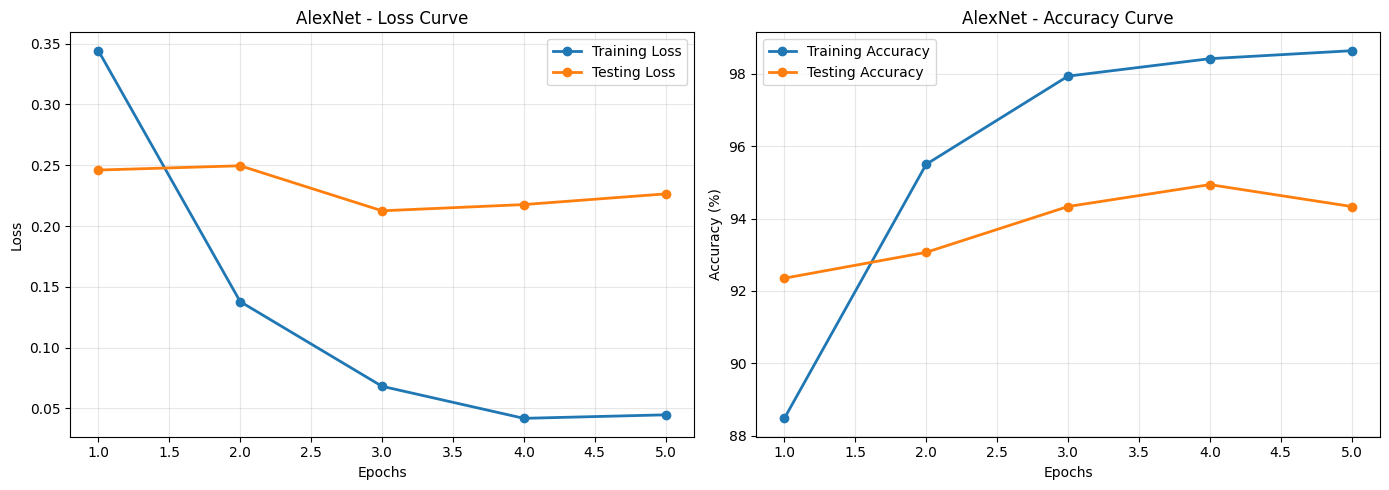


--- ALEXNET METRIC REPORT ---
Accuracy:    94.33%
Precision:   0.9362
Recall:      0.8864
Sensitivity: 0.8864 (Identical to Recall)
F1-Score:    0.9072


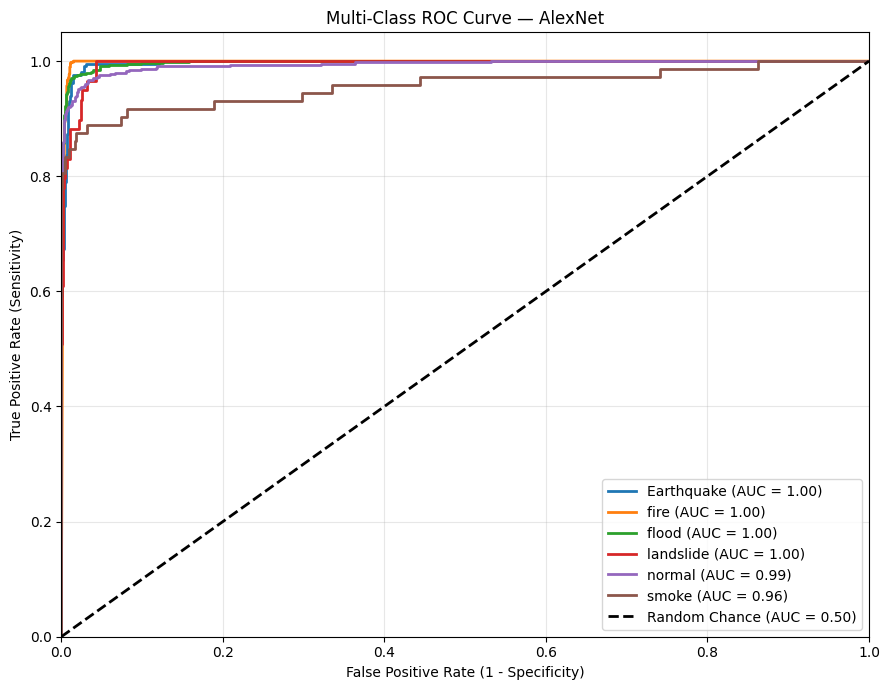


      STARTING TRAINING: GOOGLENET
Epoch [1/5] | Train Loss: 0.4713 - Train Acc: 85.28% | Test Loss: 0.1691 - Test Acc: 95.49%
Epoch [2/5] | Train Loss: 0.1131 - Train Acc: 96.93% | Test Loss: 0.1215 - Test Acc: 96.42%
Epoch [3/5] | Train Loss: 0.0463 - Train Acc: 98.87% | Test Loss: 0.1196 - Test Acc: 96.53%
Epoch [4/5] | Train Loss: 0.0233 - Train Acc: 99.50% | Test Loss: 0.1229 - Test Acc: 96.86%
Epoch [5/5] | Train Loss: 0.0224 - Train Acc: 99.56% | Test Loss: 0.1301 - Test Acc: 96.53%


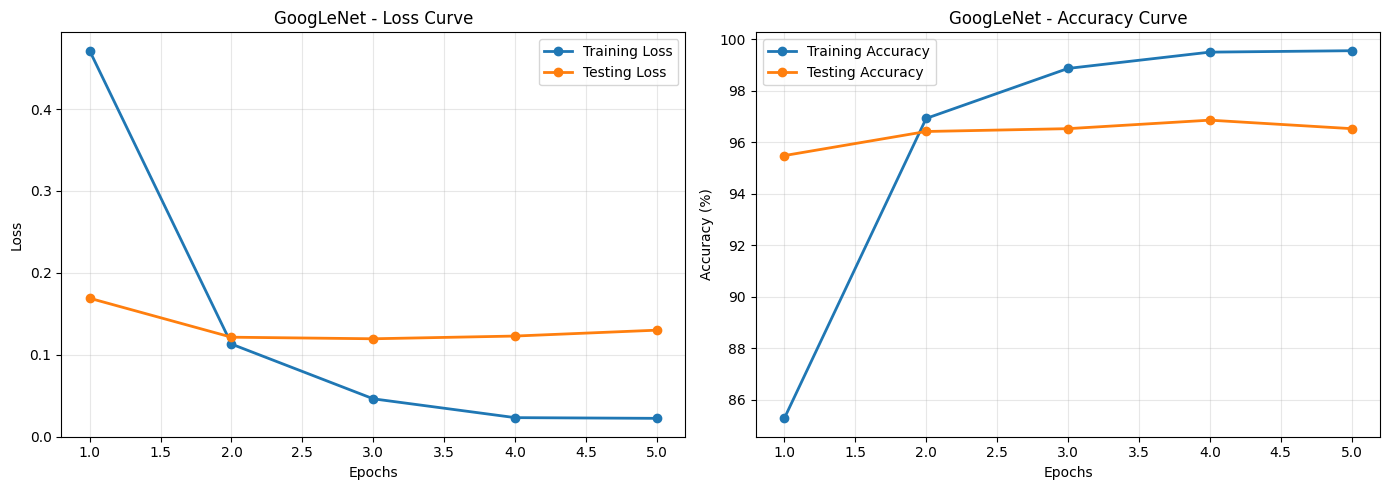


--- GOOGLENET METRIC REPORT ---
Accuracy:    96.53%
Precision:   0.9612
Recall:      0.9280
Sensitivity: 0.9280 (Identical to Recall)
F1-Score:    0.9426


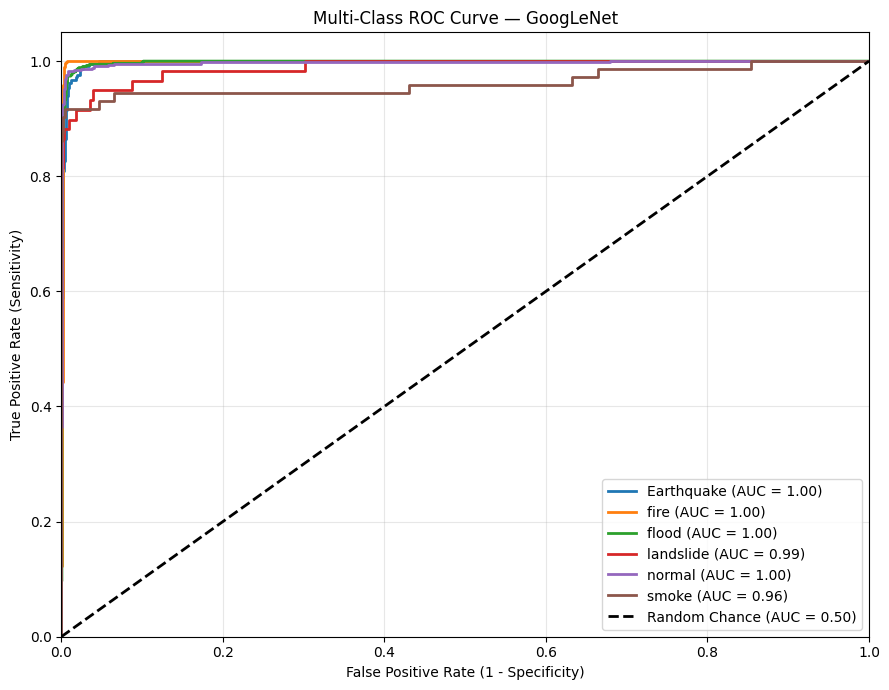

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

def train_and_evaluate(model, model_name, epochs=5):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    print(f"\n==========================================")
    print(f"      STARTING TRAINING: {model_name.upper()}")
    print(f"==========================================")

    # Dictionary to track metrics for the curves
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

    # 1. Training Phase with Epoch-by-Epoch Tracking
    for epoch in range(epochs):
        # --- TRAINING PASS ---
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += torch.sum(preds == labels).item()
            total_train += labels.size(0)

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = (correct_train / total_train) * 100

        # --- TESTING PASS ---
        model.eval()
        val_loss, correct_test, total_test = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct_test += torch.sum(preds == labels).item()
                total_test += labels.size(0)
                
        epoch_test_loss = val_loss / total_test
        epoch_test_acc = (correct_test / total_test) * 100

        # Save metrics to history
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['test_loss'].append(epoch_test_loss)
        history['test_acc'].append(epoch_test_acc)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | Test Loss: {epoch_test_loss:.4f} - Test Acc: {epoch_test_acc:.2f}%")

    # 2. Plot Accuracy and Loss Curves
    epochs_range = range(1, epochs + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Loss Curve
    ax1.plot(epochs_range, history['train_loss'], label='Training Loss', marker='o', linewidth=2)
    ax1.plot(epochs_range, history['test_loss'], label='Testing Loss', marker='o', linewidth=2)
    ax1.set_title(f'{model_name} - Loss Curve')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Accuracy Curve
    ax2.plot(epochs_range, history['train_acc'], label='Training Accuracy', marker='o', linewidth=2)
    ax2.plot(epochs_range, history['test_acc'], label='Testing Accuracy', marker='o', linewidth=2)
    ax2.set_title(f'{model_name} - Accuracy Curve')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

    # 3. Final Evaluation Phase (Metrics & ROC)
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)

            probs = torch.softmax(outputs, dim=1)
            all_probs.extend(probs.cpu().numpy())

            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    acc = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)

    print(f"\n--- {model_name.upper()} METRIC REPORT ---")
    print(f"Accuracy:    {acc * 100:.2f}%")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"Sensitivity: {recall:.4f} (Identical to Recall)")
    print(f"F1-Score:    {f1:.4f}")

    binarized_labels = label_binarize(all_labels, classes=[i for i in range(num_classes)])

    plt.figure(figsize=(9, 7))
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(binarized_labels[:, i], all_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{classes[i]} (AUC = {roc_auc:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Chance (AUC = 0.50)')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.title(f'Multi-Class ROC Curve — {model_name}')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Execute for AlexNet
train_and_evaluate(alexnet, "AlexNet", epochs=5)

# Execute for GoogLeNet
train_and_evaluate(googlenet, "GoogLeNet", epochs=5)

Generating Confusion Matrix for AlexNet...


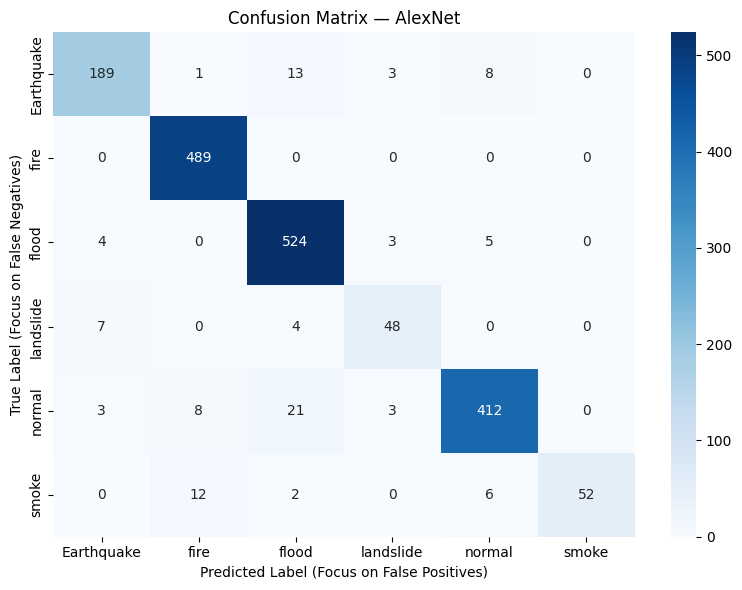

Generating Confusion Matrix for GoogLeNet...


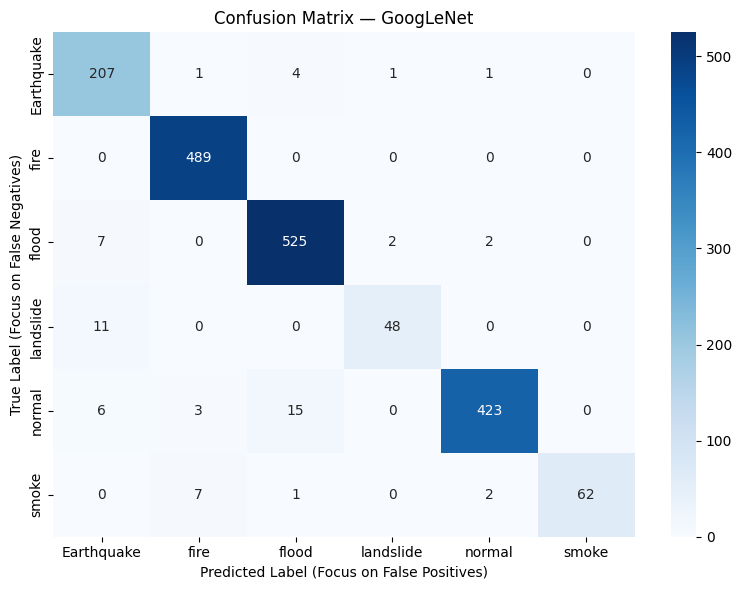

In [4]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def generate_confusion_matrix(model, model_name):
    print(f"Generating Confusion Matrix for {model_name}...")
    model.eval()
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    # Calculate raw TP, TN, FP, FN combinations
    cm = confusion_matrix(all_labels, all_preds)

    # Plot the Heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=classes, yticklabels=classes)
    plt.title(f'Confusion Matrix — {model_name}')
    plt.xlabel('Predicted Label (Focus on False Positives)')
    plt.ylabel('True Label (Focus on False Negatives)')
    plt.tight_layout()
    plt.show()

# Generate heatmaps for both trained models
generate_confusion_matrix(alexnet, "AlexNet")
generate_confusion_matrix(googlenet, "GoogLeNet")